# 01 — esc_etc as an exposure time calculator

`esc_etc` is the exposure time calculator (ETC) for the **ExtraSolar Camera (ESC)**, the
coronagraphic instrument on the Lazuli Space Observatory: a 3 m telescope, a charge-6 vortex
focal-plane mask, a deformable mirror that digs a dark hole of raw contrast ~$10^{-8}$, and twelve
filters between 400 and 730 nm. The question it answers is *"how long until this planet, at this
contrast and separation, reaches S/N = 5?"*

A **web version** of the same calculator is at <https://simulators.schmidtobservatorysystem.org/esc/>:
use it for a quick number, and these notebooks when you want sweeps, plots and the full model.

The model is analytic: five count rates in a resolution-element-sized aperture (planet, residual
starlight "speckles", zodiacal light, exozodiacal light, and the host star for saturation), with a
speckle noise floor that post-processing can only partly remove.

In this notebook:
1. a simulation: `Simulation.from_default()`,
2. S/N for a total time, and time for a target S/N,
3. the count-rate budget,
4. S/N versus time and the **plateau**.

**Jupyter AI.** These notebooks are written to be run with the Jupyter AI chat open in the side
panel. Boxes marked 🤖 suggest things to ask it; boxes marked ✏️ ask you to guess a number before
computing it.

In [1]:
import warnings
import numpy as np
import astropy.units as u
import matplotlib.pyplot as plt
import esc_etc
from esc_etc import Simulation, use_lazuli_style

use_lazuli_style()
warnings.filterwarnings("ignore", module="synphot")

***
## 1. A simulation

`from_default` builds everything from the bundled Lazuli and ESC configuration: give it the host
star magnitude (and the band it is quoted in), the planet's delta magnitude relative to the host
(20 mag = contrast $10^{-8}$), the raw dark-hole contrast, the post-processing gain, the separation
in arcseconds and the filter. The scene here is a Sun twin at 10 pc with a Jupiter-like planet at
4 AU, i.e. 0.4".

In [2]:
sim = Simulation.from_default(filter="R3", hoststarmag=4.83, hoststar_band="johnson_v",
                              planetdeltamag=20, contrast=1e-8, ppgain=10, separation=0.4)

for part in (sim.sensor, sim.coronagraph):
    print(f"--- {type(part).__name__}")
    part.describe()
st, pl = sim.scene.star, sim.scene.planet
print(f"--- Scene: star {st.mag} ({st.mag_system}, {st.band}), planet {pl.deltamag} mag fainter in the ESC band, "
      f"zodi {sim.scene.zodi.mag} mag/arcsec², exozodi {sim.scene.exozodi.mag:.2f} mag/arcsec²")

--- Sensor
read_noise = 1.832077426554004 electron(1/2) / pix(1/2)
dark_current = 0.0026523364364736 electron / (pix s)
gain = 0.9239970596457494 electron / ct
well_depth = 15260.992347242305 electron / pix
peak_pixel_fraction = 0.06310257059962165
headroom = 0.8
aperture = resel
encircled_energy = None
--- Coronagraph
raw_dh_contrast = 1e-08
ppgain = 10
separation = 0.4
subtraction = none
ref_brightness_ratio = 1.0
ref_time_ratio = 1.0
--- Scene: star 4.83 (vega, johnson_v), planet 20 mag fainter in the ESC band, zodi 22.5 mag/arcsec², exozodi 25.83 mag/arcsec²


***
## 2. S/N for a time, time for an S/N

`get_snr(total_time, frame_time)` takes plain seconds or astropy quantities. The total time is
split into frames of `frame_time`, and the read noise is paid once per frame (notebook 04).

In [3]:
r = sim.get_snr(total_time=3600, frame_time=100)
for k, v in r.items():
    print(f"{k:18s} {v}")

snr                4.586570487051768
signal_e           301.4509411790691
noise_e            65.72469387096257
reference_noise_e  0.0
science_time       3600.0 s
charged_time       3600.0 s
M                  0.008373637254974177 electron / s


- `signal_e`, `noise_e`: planet electrons in the aperture and the total noise.
- `M`: the speckle noise floor rate, the residual starlight that post-processing leaves behind.
- `science_time` and `charged_time` differ only with reference-star subtraction (notebook 03).

The inverse: `get_int_time_for_snr` returns the exact (`int_time_continuous`) and whole-frame
(`int_time`) integration time, and **NaN when the S/N is unreachable** because of the floor.

In [4]:
for snr in (3, 5, 9, 20):
    t = sim.get_int_time_for_snr(snr, frame_time=100)
    print(f"S/N = {snr:2d}: {t['int_time_continuous'][0].to(u.hr):.2f}  ({t['int_time'][0]:.0f} in whole frames)")

S/N =  3: 0.37 h  (1400 s in whole frames)


S/N =  5: 1.25 h  (4600 s in whole frames)


S/N =  9: 16.00 h  (57700 s in whole frames)


S/N = 20: nan h  (nan s in whole frames)


***
## 3. The count-rate budget

`count_rate_components()` gives the five rates in the photometric aperture. The host star's rate
is what lands on the detector *without* the coronagraph; the speckle rate is the host times the raw
contrast times the mask throughput.

source  : 8.374e-02 electron / s
speckle : 8.374e-02 electron / s
zodi    : 3.408e-03 electron / s
exozodi : 9.536e-05 electron / s
host    : 1.837e+07 electron / s


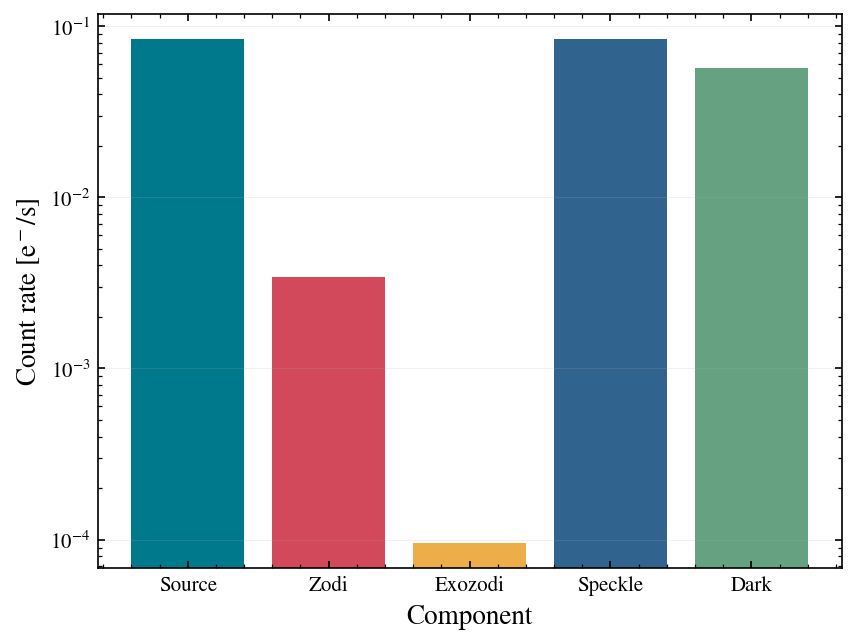

In [5]:
rates = sim.count_rate_components()
for name in ("source", "speckle", "zodi", "exozodi", "host"):
    print(f"{name:8s}: {getattr(rates, name):.3e}")
fig, ax = sim.plot_count_rates()
plt.show()

***
## 4. S/N versus time, and the plateau

With $S$ the planet rate, $B$ the background rates, and $M$ the speckle floor rate,

$$\mathrm{S/N}(t) = \frac{S\,t}{\sqrt{S\,t + B\,t + n_\mathrm{pix}\,n_\mathrm{reads}\,\sigma_\mathrm{read}^2 + (M\,t)^2}}
\;\xrightarrow{t\to\infty}\; \frac{S}{M} = \frac{C_\mathrm{planet}}{C_\mathrm{raw}}\,\mathrm{ppgain}.$$

The floor term grows as $t$, not $\sqrt{t}$, so the S/N saturates at a **plateau** set by the
planet-to-raw contrast ratio and the post-processing gain. No amount of time gets past it.

> ✏️ **Before you run the next cell:** this planet reaches S/N 4.6 in one hour. What S/N does it reach in ten hours? In a hundred? Write your guess down (or put it in the room poll), then run.

   1 h: S/N = 4.59
  10 h: S/N = 8.53
 100 h: S/N = 9.82
plateau S/N = S / M = 10.00  (= ppgain x C_planet / C_raw = 10 x 1e-8 / 1e-8)


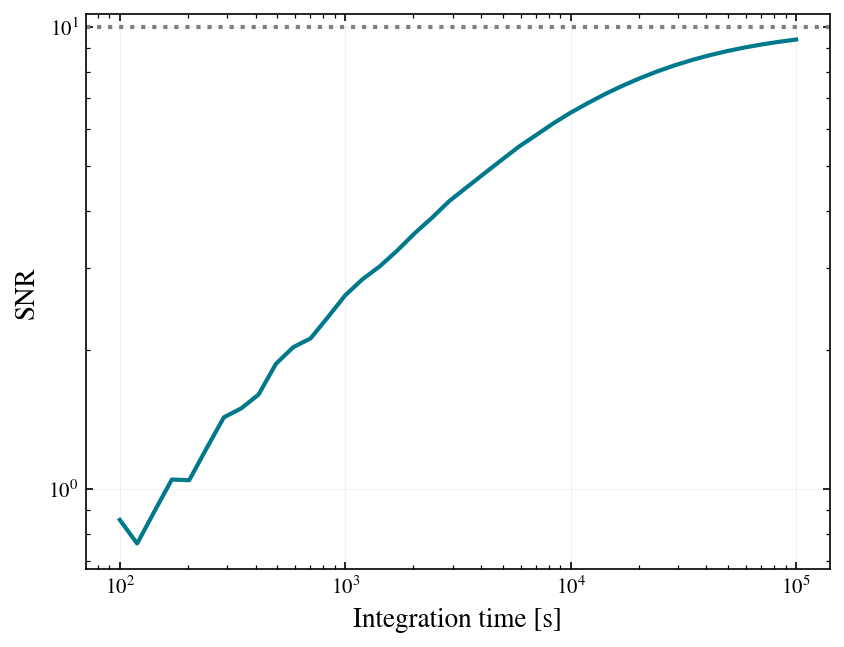

In [6]:
for hours in (1, 10, 100):
    print(f"{hours:4d} h: S/N = {sim.get_snr(hours * u.hr, 100)['snr']:.2f}")
print(f"plateau S/N = S / M = {rates.source / r['M']:.2f}  (= ppgain x C_planet / C_raw = 10 x 1e-8 / 1e-8)")
fig, ax = sim.plot_snr_vs_time()
ax.axhline(10, color="0.5", ls=":")
plt.show()

> 🤖 **Ask Jupyter AI:** *Turn the S/N-at-one-hour computation into a loop over the twelve ESC filters (esc_etc.FILTERS) and print a table of filter, central wavelength (sim.telescope.primary_filter) and S/N in one hour, sorted by S/N.*
>
> Notebook 02 does the same; compare. Ask it why the wide filters win so clearly.

`plot()` draws the six-panel overview: spectra, bandpass, aperture, mask throughput, rates and
S/N versus time.

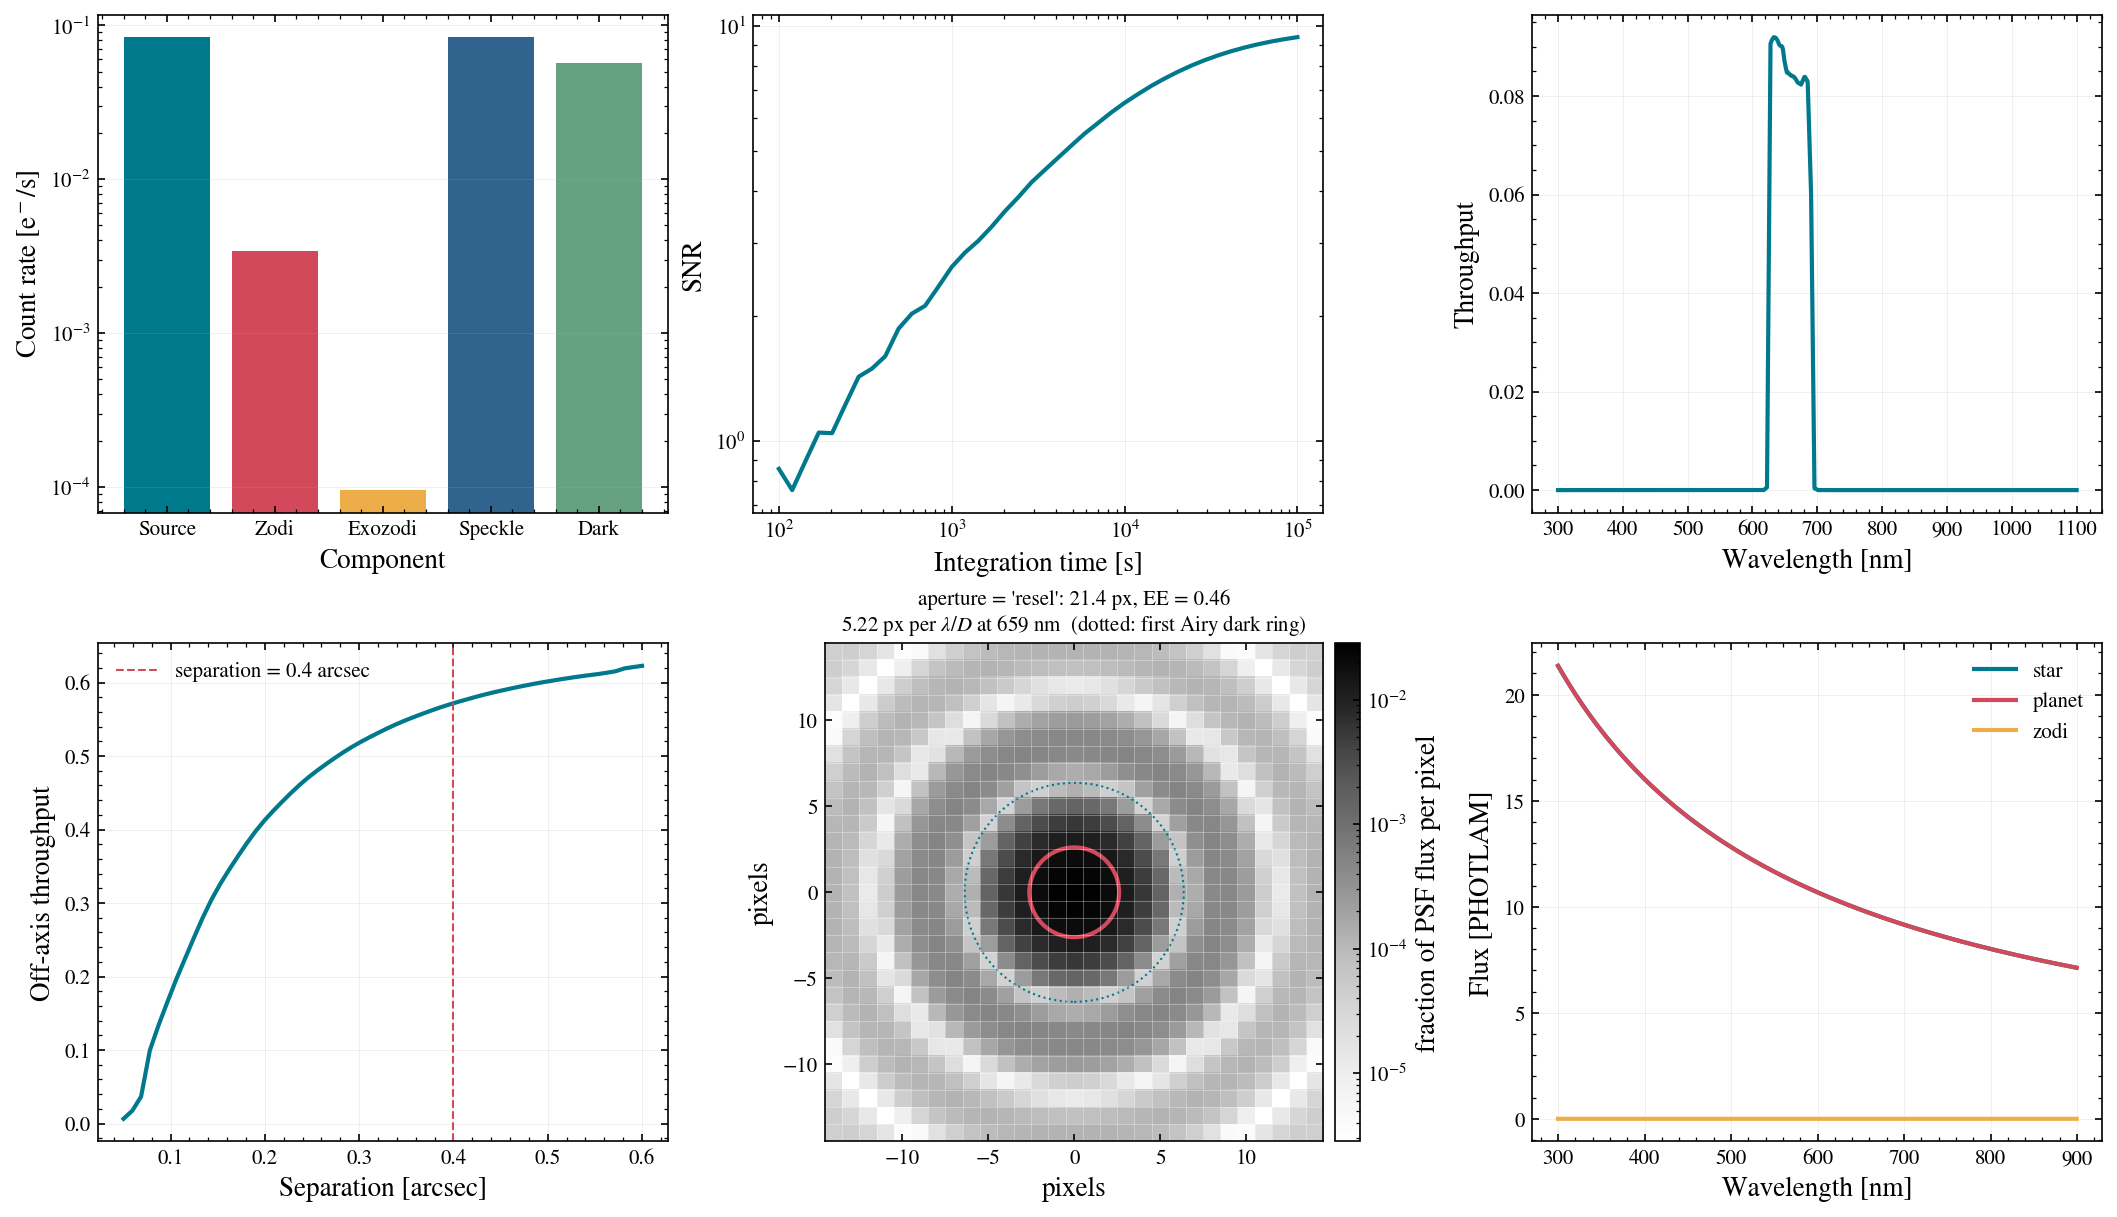

In [7]:
fig, axes = sim.plot()
plt.show()

***
## Summary

```python
sim = Simulation.from_default(filter="R3", hoststarmag=4.83, hoststar_band="johnson_v",
                              planetdeltamag=20, contrast=1e-8, ppgain=10, separation=0.4)
sim.get_snr(3600, 100)["snr"]                                   # S/N in 1 h of 100 s frames
sim.get_int_time_for_snr(5, 100)["int_time_continuous"][0]      # time to S/N 5 (NaN above the plateau)
sim.count_rate_components()                                     # planet, speckle, zodi, exozodi, host
sim.plot_snr_vs_time(); sim.plot()
```

Next: [02 — components, parameters and filters](02_components_and_filters.ipynb).